In [1]:
import numpy as np  #numpy: https://numpy.org/doc/stable/index.html
import importlib.util  #importlib: https://docs.python.org/3/library/importlib.html
from scipy.spatial import cKDTree
from astropy.table import Table
from numpy.lib import recfunctions as rfn
import matplotlib
import matplotlib.pyplot as plt
import time
import voronoi

def ltime(date=False):
    tm=time.localtime()
    datestr=str(tm.tm_mday)+'/'+str(tm.tm_mon)+'/'+str(tm.tm_year)
    tmstr=str(tm.tm_hour)+':'+str(tm.tm_min)+':'+str(tm.tm_sec)

    if(date):
        tmstr=datestr+' '+tmstr

    return tmstr

import os, sys
root = "/mnt/home/project/csatsangi.chetan/projects"
sys.path.insert(0, os.path.join(root, "sahyadri-sandbox", "scripts", "post-process"))

In [25]:
#Load data:
centrals = Table.read('centrals_sim.fits').as_array()
satellites = Table.read('satellites_sim.fits').as_array()
centrals_trimmed = rfn.drop_fields(centrals, ('Nsat','rvir'), usemask=False)
all_galaxies = np.concatenate([centrals_trimmed, satellites])

gpos = np.zeros((all_galaxies.shape[0], 3), dtype='float')
gpos[:,0] = all_galaxies['x']
gpos[:,1] = all_galaxies['y']
gpos[:,2] = all_galaxies['z']

#Parameters:
Ntrc = gpos.shape[0]
Lbox = 200.0
seed = 10
percentiles = np.arange(1, 100)
gpos = gpos%Lbox

## We have the data loaded. Now all we have to do is compute the vvf for different jackknife realizations
1. Store different jacnkknife realizations's positions
2. find their vvf for ranfac=10,000 parallelly
3. find the covarianvce matrix 

In [26]:
gpos.shape

(339777, 3)

In [30]:
from jackknife import JackKnife
JackIt =  JackKnife(gpos, Lbox)
njn=144
gpos_jn2,_ = JackIt.add_jackknife_regions(njn=njn, los=1) #returns a new array with an added column for jackknife region number
gpos_jn2.shape
Table(gpos_jn2).write(f'real_results/gpos_jackknife_rsd_{njn}.fits', overwrite=True)

In [24]:
gpos_jn = Table.read('gpos_jackknife_rsd.fits').as_array()

In [25]:
gpos_jn.dtype.names

('col0', 'col1', 'col2', 'col3')

In [4]:
gpos_jn = Table.read('gpos_jackknife_rsd.fits').as_array()

gpos = np.zeros((gpos_jn.shape[0], 4), dtype='float')
gpos[:,0] = gpos_jn['col0']
gpos[:,1] = gpos_jn['col1']
gpos[:,2] = gpos_jn['col2']
gpos[:,3] = gpos_jn['col3']

njn = len(np.unique(gpos_jn['col3']))

In [5]:
njn

100

## Loading the jackknife results(after running compute_voronoi.py)

In [2]:
jackknife_vvf_100 = Table.read('rsd_results/vvf_results_100.fits').as_array()
jackknife_vvf_64 = Table.read('rsd_results/vvf_results_64.fits').as_array()
jackknife_vvf_144 = Table.read('rsd_results/vvf_results_144.fits').as_array()

In [4]:
jackknife_vvf_100.dtype.names

('perc', 'vvf_mean', 'vvf_err', 'vvf_all', 'vvf_realizations')

In [14]:
jackknife_vvf_100

array([( 2.5, 0.01430643, 0.00143791, 0.0143, [0.0143   , 0.0142   , 0.0143   , 0.0143   , 0.0142   , 0.0142725, 0.0146   , 0.0144   , 0.0143   , 0.0142   , 0.0143   , 0.0144   , 0.0142   , 0.0142   , 0.0143   , 0.0144   , 0.0143   , 0.0143   , 0.0143   , 0.0143   , 0.0143   , 0.0152   , 0.0142   , 0.0142   , 0.0142   , 0.0143   , 0.0143   , 0.0143   , 0.0143   , 0.0142   , 0.0143   , 0.0143   , 0.0143   , 0.0142   , 0.0143   , 0.0143   , 0.0142   , 0.0143   , 0.0143   , 0.0143   , 0.0142   , 0.0143   , 0.0142   , 0.0143   , 0.0143   , 0.0143   , 0.0142   , 0.0143   , 0.0142   , 0.0143175, 0.0143   , 0.0142   , 0.0142   , 0.0142   , 0.0142   , 0.0143   , 0.0143   , 0.0143   , 0.0143   , 0.0142   , 0.0143   , 0.0143975, 0.0142   , 0.0142   , 0.0142   , 0.0145   , 0.0143   , 0.0143   , 0.0143   , 0.0143   , 0.0142   , 0.0142   , 0.0144   , 0.0143   , 0.0143   , 0.0142   , 0.0142   , 0.0143   , 0.0143   , 0.0144   , 0.0143   , 0.0142   , 0.0143   , 0.0143   , 0.0143   , 0.0146   , 0.0143 

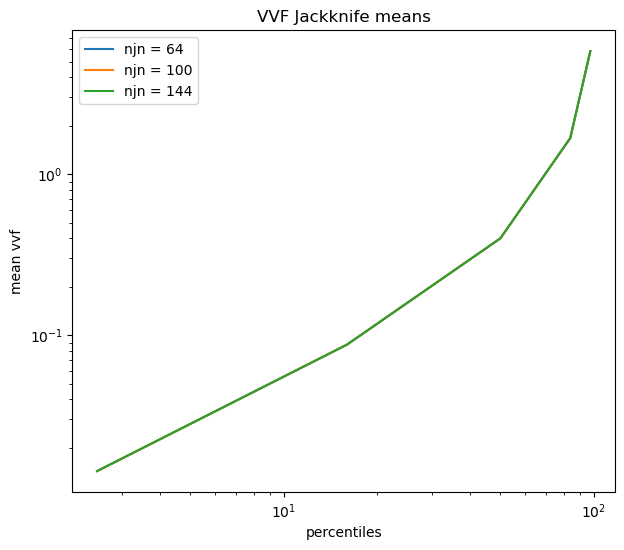

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.loglog(jackknife_vvf_64['perc'], jackknife_vvf_64['vvf_mean'], label='njn = 64')
ax.loglog(jackknife_vvf_100['perc'], jackknife_vvf_100['vvf_mean'], label='njn = 100')
ax.loglog(jackknife_vvf_144['perc'], jackknife_vvf_144['vvf_mean'], label='njn = 144')
plt.title('VVF Jackknife means')
plt.xlabel('percentiles')
plt.ylabel('mean vvf')
ax.legend()
fig.savefig('rsd_results/mean_jackcknife.png', dpi=150)
plt.show()

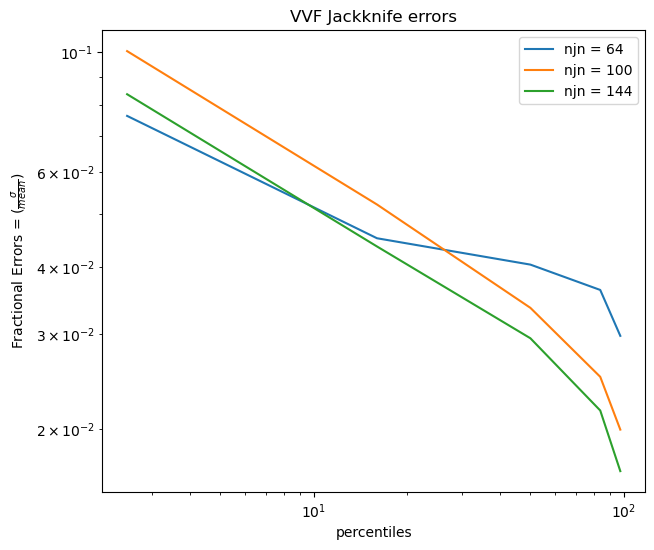

In [31]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.loglog(jackknife_vvf_64['perc'], jackknife_vvf_64['vvf_err']/jackknife_vvf_64['vvf_mean'], label='njn = 64')
ax.loglog(jackknife_vvf_100['perc'], jackknife_vvf_100['vvf_err']/jackknife_vvf_100['vvf_mean'], label='njn = 100')
ax.loglog(jackknife_vvf_144['perc'], jackknife_vvf_144['vvf_err']/jackknife_vvf_144['vvf_mean'], label='njn = 144')
plt.title('VVF Jackknife errors')
plt.xlabel('percentiles')
plt.ylabel(r'Fractional Errors = $(\frac{\sigma}{mean})$')
ax.legend()
fig.savefig('rsd_results/fractional_errors.png', dpi=150)
plt.show()


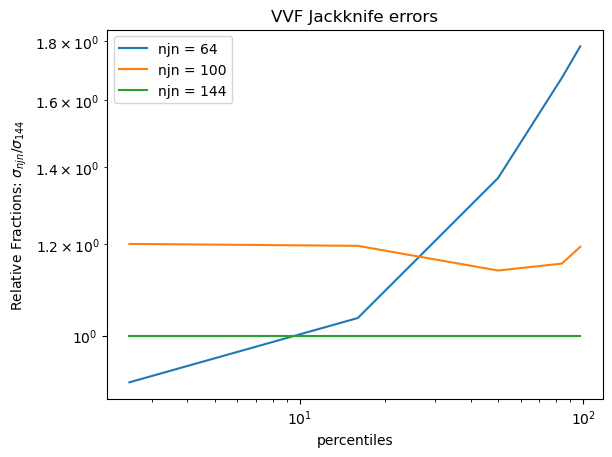

In [18]:
plt.loglog(jackknife_vvf_64['perc'], jackknife_vvf_64['vvf_err']/jackknife_vvf_144['vvf_err'], label='njn = 64')
plt.loglog(jackknife_vvf_100['perc'], jackknife_vvf_100['vvf_err']/jackknife_vvf_144['vvf_err'], label='njn = 100')
plt.loglog(jackknife_vvf_144['perc'], jackknife_vvf_144['vvf_err']/jackknife_vvf_144['vvf_err'], label='njn = 144')
plt.title('VVF Jackknife errors')
plt.xlabel('percentiles')
plt.ylabel(r'Relative Fractions: $\sigma_{njn}/\sigma_{144}$')
plt.legend()
plt.show()

In [9]:
# Load the output files (assuming you ran 64, 125, and 144)
njn_list = [64, 100, 144]
colors = ['blue', 'orange', 'green']

plt.figure(figsize=(10, 6))

for njn, color in zip(njn_list, colors):
    try:
        data = Table.read(f'vvf_results_{njn}.fits')
        perc = data['perc']
        err = data['vvf_err']
        
        plt.plot(perc, err, label=f'njn = {njn}', color=color, marker='o', linestyle='-')
    except FileNotFoundError:
        print(f"File vvf_results_{njn}.fits not found. Skipping.")

plt.title('Jackknife Error Convergence for Voronoi Volumes')
plt.xlabel('Percentile')
plt.ylabel('Estimated Jackknife Error (vvf_err)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

array([0., 0., 0., 0., 0.])

In [19]:
jackknife_vvf['vvf_err']

array([0.00143791, 0.00455782, 0.01339711, 0.04184136, 0.115792  ])

## Building the Covariance matrix
$$\mathbf{C} = \frac{N_{jn} - 1}{N_{jn}} \sum_{k=1}^{N_{jn}} \left( \mathbf{y}^{(k)} - \mathbf{\bar{y}} \right) \left( \mathbf{y}^{(k)} - \mathbf{\bar{y}} \right)^T$$

In [22]:
vvf_realizations = jackknife_vvf_100['vvf_realizations']
njn = vvf_realizations.shape[1]

In [23]:
# 1. Calculate the mean across the jackknife regions (shape: n_percentiles)
vvf_mean_jn = np.mean(vvf_realizations, axis=1)

# 2. Calculate the deviations from the mean (shape: n_percentiles, njn)
# The [:, None] broadcasts the 1D mean array across the njn columns
delta = vvf_realizations - vvf_mean_jn[:, None]

# 3. Compute the Jackknife covariance matrix (shape: n_percentiles, n_percentiles)
cov_matrix = ((njn - 1) / njn) * (delta @ delta.T)

# 4. Invert to get the precision matrix
precision_matrix = np.linalg.inv(cov_matrix)


In [25]:
cov_matrix.shape

(5, 5)